# Field Shift Â· Punto 1: dividir el lote en sectores

**Objetivo final:** que el productor vea su lote pintado por sectores (por ejemplo "loma seca", "bajo hÃºmedo", "zona media") y, para cada sector, cÃ³mo le fue en los aÃ±os secos, normales y hÃºmedos comparado con el resto del lote.

**Datos:** los 10 lotes de demostraciÃ³n de la entrega `fieldshift_datos_v1.3/lotes` (Iowa, Illinois e Indiana). Cada lote estÃ¡ dividido en pÃ­xeles de 30 Ã— 30 m, y de cada pÃ­xel tenemos:

- el **vigor** del cultivo de cada aÃ±o, medido por satÃ©lite (NDVI de julioâ€“agosto, Landsat);
- quÃ© **cultivo** habÃ­a cada aÃ±o (Cropland Data Layer del USDA);
- el **terreno** (USGS 3DEP, un mapa de elevaciÃ³n de 10 m hecho con lidar): elevaciÃ³n, pendiente, por dÃ³nde corre y se junta el agua;
- el **suelo** (SSURGO): agua que puede guardar, drenaje natural;
- si tiene **drenaje con caÃ±os** enterrados (mapa AgTile-US).

**Problema:** no hay rinde por lote (ninguna fuente pÃºblica lo tiene). Usamos el vigor como indicador: **no es rinde**.

La notebook tiene dos partes:

- **Parte A, elegir el mÃ©todo:** comparamos varias formas de armar los sectores (reglas simples, k-means, fuzzy c-means, mezcla gaussiana bayesiana) con una prueba honesta: armar los sectores sin un aÃ±o y ver si explican el vigor de ese aÃ±o.
- **Parte B, sectores para la app:** con el mÃ©todo ganador armamos los sectores finales, decidimos si el lote tiene sectores claros, dÃ©biles o es parejo, les ponemos nombre, medimos la confianza en aÃ±os que no se usaron y guardamos las tablas en `backend/Datos/`.

CÃ³mo usarla: abrila desde cualquier carpeta del repo y corrÃ© las celdas de arriba hacia abajo (Shift + Enter). Si no encuentra los datos, las celdas imprimen "queda en espera" en vez de fallar. Tarda unos minutos (el paso 7 es el mÃ¡s largo).

## 0. Instalar y cargar librerÃ­as

- **pandas:** maneja tablas, como un Excel desde Python.
- **numpy:** cuentas con nÃºmeros.
- **scikit-learn:** trae k-means, la mezcla gaussiana bayesiana y PCA (una forma de resumir muchas columnas en pocas).
- **matplotlib:** dibuja los mapas.

Fuzzy c-means y mean shift no vienen en scikit-learn: los programamos acÃ¡ en pocas lÃ­neas, asÃ­ no hace falta instalar nada mÃ¡s. Si te falta alguna librerÃ­a, sacale el `#` a la lÃ­nea de abajo y corrÃ© la celda una vez.

In [1]:
#!pip install pandas numpy scikit-learn matplotlib

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture

warnings.filterwarnings("ignore", category=RuntimeWarning)  # medias de columnas vacÃ­as: se tratan aparte
SEMILLA = 0   # misma semilla = mismos sectores cada vez que se corre
print("LibrerÃ­as cargadas.")

LibrerÃ­as cargadas.


## 1. Cargar los datos

La entrega pesa unos 450 MB (casi todo es `vegetacion_px_obs.csv`, que esta notebook no usa), asÃ­ que **no estÃ¡ en Git**. La notebook la busca en estos lugares, en orden:

1. `backend/Datos/entregas/fieldshift_datos_v1.3/lotes/` dentro del repo, donde el README de ML dice que van las entregas (esa carpeta no va a Git);
2. la carpeta `data/` que estÃ¡ al lado del repo (asÃ­ estÃ¡ en la mÃ¡quina de ML).

La entrega v2 trae la misma carpeta `lotes/` que la v1.3 (los mismos archivos), asÃ­ que si solo tenÃ©s la v2, tambiÃ©n sirve.

Usamos solo los pÃ­xeles **interiores** (`interior == 1`): los del borde mezclan el lote con caminos, alambrados y el lote vecino.

Claves: un lote es `id_lote`; un pÃ­xel es `id_lote` + `px_id` (`px_id` se repite entre lotes). Los ids se leen como texto para no perder ceros.

In [3]:
# RaÃ­z del repo: la primera carpeta hacia arriba que tenga .git
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".git").exists())

CANDIDATAS_LOTES = [
    RAIZ / "backend" / "Datos" / "entregas" / "fieldshift_datos_v1.3" / "lotes",  # dentro del repo
    RAIZ.parent / "data" / "fieldshift_datos_v1.3" / "lotes",                     # carpeta de ML, al lado del repo
    # la v2 trae la misma carpeta lotes/ que la v1.3
    RAIZ / "backend" / "Datos" / "entregas" / "fieldshift_datos_v2" / "lotes",
    RAIZ.parent / "data" / "fieldshift_datos_v2" / "lotes",
]
RUTA_LOTES = next((p for p in CANDIDATAS_LOTES if (p / "pixeles.csv").exists()), None)

TIPOS = {"fips": str, "id_lote": str, "mukey": str}
CLAVES = ["fips", "id_lote", "px_id"]

HAY_DATOS = RUTA_LOTES is not None
if HAY_DATOS:
    lotes      = pd.read_csv(RUTA_LOTES / "lotes.csv", dtype=TIPOS)
    pixeles    = pd.read_csv(RUTA_LOTES / "pixeles.csv", dtype=TIPOS).query("interior == 1")
    terreno    = pd.read_csv(RUTA_LOTES / "terreno_px.csv", dtype=TIPOS)
    drenaje    = pd.read_csv(RUTA_LOTES / "drenaje_px.csv", dtype=TIPOS)
    cultivo_px = pd.read_csv(RUTA_LOTES / "cultivo_px_anual.csv", dtype=TIPOS,
                             usecols=CLAVES + ["anio", "cultivo"])
    suelo_px   = pd.read_csv(RUTA_LOTES / "suelo_px.csv", dtype=TIPOS)
    suelo_mk   = pd.read_csv(RUTA_LOTES / "suelo_mukey.csv", dtype=TIPOS)
    vegetacion = pd.read_csv(RUTA_LOTES / "vegetacion_px_anual.csv", dtype=TIPOS)
    lotes_anio = pd.read_csv(RUTA_LOTES / "lotes_anual.csv", dtype=TIPOS)
    clima      = pd.read_csv(RUTA_LOTES / "clima_lote_anual.csv", dtype=TIPOS)
    print("Datos en:", RUTA_LOTES)
    print("Lotes:", len(lotes), "| pÃ­xeles interiores:", len(pixeles))
else:
    print("No encontrÃ© la entrega de lotes: la notebook queda en espera.")

Datos en: C:\Users\MDP\Documents\GitHub\ML-NasaSpaceProgram\data\fieldshift_datos_v1.3\lotes
Lotes: 10 | pÃ­xeles interiores: 5334


## 2. Mirar los datos antes de modelar

Los 10 lotes vienen de cuatro **paisajes** distintos, elegidos a propÃ³sito:

- `depresiones`: Des Moines Lobe, con bajos cerrados que se anegan;
- `lomas_loess`: lomas de loess, con unos 30 m de desnivel dentro del lote;
- `llanura_control`: llanura casi plana (sirve de control: esperamos pocos sectores);
- `indiana`: llanura de till de Indiana.

Abajo, la tabla de los lotes y un mapa de la **elevaciÃ³n relativa** de cada uno: cuÃ¡ntos metros estÃ¡ cada pÃ­xel por encima (amarillo) o por debajo (violeta) de la mitad del lote. Cada mapa tiene su propia escala.

Usamos el terreno de **3DEP** y no el de NASADEM. NASADEM viene en metros enteros: las lomas y los bajos de menos de un metro casi no se ven, y en estos lotes el agua que se junta en cada pÃ­xel (TWI) casi no coincide entre los dos mapas (correlaciÃ³n 0,37). `relieve_3dep_m` es el desnivel del lote segÃºn 3DEP.

,id_lote,paisaje,area_ha,n_px_interior,relieve_3dep_m
5,19079_191825000600003,depresiones,83.0,795,7.4
6,19079_191825001174693,depresiones,109.8,1071,7.7
7,19079_191825002094751,depresiones,57.8,549,9.1
2,18157_181825000203707,indiana,61.6,581,8.3
3,18157_181825001116483,indiana,40.3,365,2.5
0,17019_171825005060041,llanura_control,47.6,435,2.7
1,17019_171825005511042,llanura_control,39.2,349,1.6
4,19047_191825002083543,lomas_loess,46.5,419,26.1
8,19165_191825001638480,lomas_loess,44.2,399,31.2
9,19165_191825002368896,lomas_loess,39.6,371,27.1


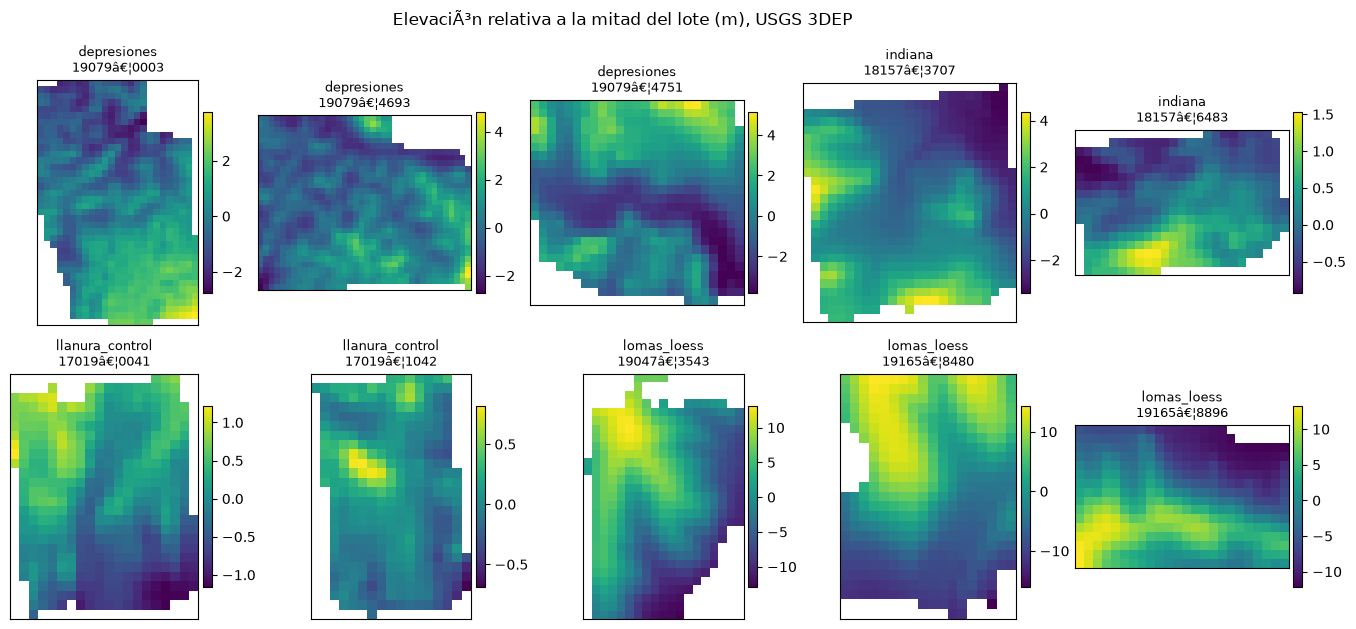

In [4]:
def grilla(d):
    # Fila y columna de cada pÃ­xel en la grilla de 30 m (fila 0 = norte)
    col = ((d["x_m"] - d["x_m"].min()) / 30).round().astype(int).to_numpy()
    fil = ((d["y_m"].max() - d["y_m"]) / 30).round().astype(int).to_numpy()
    return fil, col


def dibujar_lotes(tabla, columna, titulo, categorias=None, colores=None, cmap="viridis", subtitulos=None):
    # Un mapa chico por lote, ordenados por paisaje
    ids = list(lotes.sort_values(["paisaje", "id_lote"])["id_lote"])
    fig, ejes = plt.subplots(2, 5, figsize=(17, 7))
    for eje, id_lote in zip(ejes.flat, ids):
        d = tabla[tabla["id_lote"] == id_lote]
        fil, col = grilla(d)
        M = np.full((fil.max() + 1, col.max() + 1), np.nan)
        if categorias is None:
            M[fil, col] = d[columna].to_numpy(float)
            im = eje.imshow(M, cmap=cmap, interpolation="nearest")
            fig.colorbar(im, ax=eje, fraction=0.04, pad=0.02)
        else:
            M[fil, col] = d[columna].map({c: i for i, c in enumerate(categorias)}).to_numpy(float)
            eje.imshow(M, cmap=ListedColormap(colores), vmin=-0.5, vmax=len(categorias) - 0.5,
                       interpolation="nearest")
        paisaje = lotes.set_index("id_lote").loc[id_lote, "paisaje"]
        texto = f"{paisaje}\n{id_lote[:5]}â€¦{id_lote[-4:]}"
        if subtitulos is not None:
            texto += "\n" + subtitulos.get(id_lote, "")
        eje.set_title(texto, fontsize=9)
        eje.set_xticks([]); eje.set_yticks([])
    if categorias is not None:
        fig.legend([Patch(color=c) for c in colores], categorias, loc="lower center", ncol=len(categorias))
    fig.suptitle(titulo)
    plt.show()


if HAY_DATOS:
    px = (pixeles[CLAVES + ["x_m", "y_m"]]
          .merge(terreno, on=CLAVES, validate="one_to_one")
          .merge(drenaje, on=CLAVES, how="left", validate="one_to_one"))
    px["elev_rel_m"] = px["elevacion_3dep_m"] - px.groupby("id_lote")["elevacion_3dep_m"].transform("median")
    display(lotes[["id_lote", "paisaje", "area_ha", "n_px_interior", "relieve_3dep_m"]]
            .sort_values(["paisaje", "id_lote"]).round(1))
    dibujar_lotes(px, "elev_rel_m", "ElevaciÃ³n relativa a la mitad del lote (m), USGS 3DEP", cmap="viridis")
else:
    print("Faltan los datos de lotes: queda en espera.")

## 3. Preparar las variables

Cuatro cosas:

1. **Suelo por pÃ­xel.** Un pÃ­xel puede caer en mÃ¡s de una unidad de suelo de SSURGO: promediamos ponderando por la fracciÃ³n de cada una. Usamos el agua que el suelo puede guardar (`aws0_150_mm`) y el drenaje, pasado a un nÃºmero de 0 (excesivamente drenado) a 6 (muy pobremente drenado).
2. **AÃ±os que sirven.** Un aÃ±o entra si el lote tuvo maÃ­z o soja, no estaba partido entre cultivos y al menos la mitad de los pÃ­xeles tienen una imagen despejada de julioâ€“agosto. Antes de 2008 no sabemos quÃ© cultivo habÃ­a, asÃ­ que esos aÃ±os quedan afuera.
3. **PÃ­xeles con otro cultivo.** Si un aÃ±o el CDL dice que un pÃ­xel tenÃ­a otro cultivo que el lote (pasto en una vÃ­a de agua, soja en un lote de maÃ­z), ese aÃ±o el pÃ­xel no cuenta: su verdor no es el del cultivo del lote. En una prueba, un sector chico de un lote de Crawford (19047) tenÃ­a otro cultivo en el 69 % de sus pÃ­xel-aÃ±os, y sin este paso salÃ­a como "loma seca". Con este paso, ese lote pasa a tener sectores dÃ©biles (paso 11): buena parte de lo que separaba sus sectores era ese otro cultivo. Guardamos la marca `otro_cultivo` para avisar en el sector (paso 13).
4. **Vigor relativo de cada aÃ±o.** El NDVI cambia mucho de un aÃ±o a otro (por el clima y por el cultivo), asÃ­ que comparamos cada pÃ­xel **con el resto de su lote ese mismo aÃ±o**:
   - `vigor_z` (**puntaje z**): cuÃ¡ntos desvÃ­os estÃ¡ el pÃ­xel por encima (+) o por debajo (âˆ’) del promedio del lote. Es la escala que usa el modelo.
   - `vigor_rel_pct`: lo mismo en %, "este pÃ­xel tuvo 4 % mÃ¡s verdor que el promedio del lote". Es la que se muestra en la app.

   Las dos se calculan con un solo aÃ±o a la vez, asÃ­ que no mezclan informaciÃ³n de un aÃ±o con otro.

In [5]:
DRENAJE_ORDEN = {   # de mÃ¡s seco (0) a mÃ¡s hÃºmedo (6)
    "Excessively drained": 0, "Somewhat excessively drained": 1, "Well drained": 2,
    "Moderately well drained": 3, "Somewhat poorly drained": 4, "Poorly drained": 5,
    "Very poorly drained": 6,
}
SUELO_NUMERICO = ["aws0_150_mm", "drenaje_ord"]


def promedio_ponderado(s, columna):
    # Promedio de una columna del suelo por pÃ­xel, ponderado por la fracciÃ³n de cada unidad
    ok = s[columna].notna()
    t = s[ok].assign(_peso_x_valor=s.loc[ok, columna] * s.loc[ok, "frac_mukey"])
    g = t.groupby(CLAVES)
    return (g["_peso_x_valor"].sum() / g["frac_mukey"].sum()).rename(columna)


if HAY_DATOS:
    suelo_mk["drenaje_ord"] = suelo_mk["clase_drenaje"].map(DRENAJE_ORDEN)
    s = suelo_px.merge(suelo_mk, on="mukey")
    suelo = pd.concat([promedio_ponderado(s, c) for c in SUELO_NUMERICO], axis=1).reset_index()
    dominante = s.sort_values("frac_mukey").groupby(CLAVES).tail(1)[CLAVES + ["mukey", "clase_drenaje"]]
    px = (px.merge(suelo, on=CLAVES, how="left", validate="one_to_one")
            .merge(dominante, on=CLAVES, how="left", validate="one_to_one"))
    print("PÃ­xeles:", len(px), "| sin dato de agua Ãºtil del suelo:", px["aws0_150_mm"].isna().sum())
else:
    print("Faltan los datos de lotes: queda en espera.")

PÃ­xeles: 5334 | sin dato de agua Ãºtil del suelo: 0


Ahora los puntos 2, 3 y 4: quÃ© aÃ±os sirven en cada lote, quÃ© pÃ­xel-aÃ±os se sacan por tener otro cultivo y el vigor relativo de cada pÃ­xel en cada aÃ±o. La tabla de abajo muestra cuÃ¡ntos aÃ±os quedan por lote y quÃ© % de los pÃ­xel-aÃ±os tenÃ­a otro cultivo.

In [6]:
CULTIVOS_OK = ["maiz", "soja"]
MIN_FRAC_CON_DATO = 0.5   # al menos la mitad de los pÃ­xeles con imagen despejada en julioâ€“agosto

if HAY_DATOS:
    veg = vegetacion.merge(pixeles[CLAVES], on=CLAVES, validate="many_to_one")   # solo pÃ­xeles interiores
    veg["ndvi"] = veg["ndvi_media_jul_ago"].where(veg["n_obs_jul_ago"] >= 1)
    veg = veg.merge(lotes_anio[["id_lote", "anio", "cultivo_principal", "lote_partido"]],
                    on=["id_lote", "anio"], how="left", validate="many_to_one")
    veg = veg.merge(cultivo_px.rename(columns={"cultivo": "cultivo_px"}),
                    on=CLAVES + ["anio"], how="left", validate="one_to_one")
    frac = veg.groupby(["id_lote", "anio"])["ndvi"].transform(lambda x: x.notna().mean())
    sirve = (veg["cultivo_principal"].isin(CULTIVOS_OK) & (veg["lote_partido"] == 0)
             & (frac >= MIN_FRAC_CON_DATO))
    veg = veg[sirve].copy()

    # PÃ­xel-aÃ±o con otro cultivo que el lote: no cuenta (si el CDL no tiene dato, se deja)
    veg["otro_cultivo"] = veg["cultivo_px"].notna() & (veg["cultivo_px"] != veg["cultivo_principal"])
    veg["ndvi"] = veg["ndvi"].mask(veg["otro_cultivo"])

    g = veg.groupby(["id_lote", "anio"])["ndvi"]
    veg["vigor_z"] = (veg["ndvi"] - g.transform("mean")) / g.transform("std")
    veg["vigor_rel_pct"] = 100 * (veg["ndvi"] / g.transform("mean") - 1)

    ANIOS = veg.groupby("id_lote")["anio"].apply(lambda a: sorted(a.unique())).to_dict()
    tabla = pd.DataFrame({
        "paisaje": lotes.set_index("id_lote")["paisaje"],
        "anios_que_sirven": pd.Series({k: len(v) for k, v in ANIOS.items()}),
        "desde": pd.Series({k: min(v) for k, v in ANIOS.items()}),
        "hasta": pd.Series({k: max(v) for k, v in ANIOS.items()}),
        "pct_px_anios_otro_cultivo": 100 * veg.groupby("id_lote")["otro_cultivo"].mean(),
    }).sort_values("paisaje").round(1)
    display(tabla)
else:
    print("Faltan los datos de lotes: queda en espera.")

,paisaje,anios_que_sirven,desde,hasta,pct_px_anios_otro_cultivo
19079_191825000600003,depresiones,11,2011,2025,0.0
19079_191825001174693,depresiones,13,2008,2025,0.4
19079_191825002094751,depresiones,14,2008,2025,0.5
18157_181825000203707,indiana,18,2008,2025,0.9
18157_181825001116483,indiana,18,2008,2025,1.2
17019_171825005060041,llanura_control,17,2008,2025,0.1
17019_171825005511042,llanura_control,14,2011,2025,0.5
19047_191825002083543,lomas_loess,16,2008,2025,2.6
19165_191825001638480,lomas_loess,12,2012,2025,1.0
19165_191825002368896,lomas_loess,14,2008,2025,0.2


**AÃ±os secos, normales y hÃºmedos.** Para cada lote ordenamos sus aÃ±os por el **dÃ©ficit de agua de la temporada** (lluvia menos lo que pide la atmÃ³sfera, abrilâ€“septiembre, NASA POWER en el centro del lote): el tercio con mÃ¡s dÃ©ficit es `seco`, el tercio con menos es `humedo` y el resto `normal`. La funciÃ³n recibe la lista de aÃ±os a usar, asÃ­ en la validaciÃ³n los cortes salen solo de los aÃ±os de entrenamiento.

In [7]:
def clasificar_anios(id_lote, anios):
    c = clima[(clima["id_lote"] == id_lote) & clima["anio"].isin(anios)][["anio", "deficit_temporada_mm"]].copy()
    q1, q2 = c["deficit_temporada_mm"].quantile([1 / 3, 2 / 3])
    c["clase_anio"] = np.select([c["deficit_temporada_mm"] <= q1, c["deficit_temporada_mm"] >= q2],
                                ["seco", "humedo"], "normal")
    return c[["anio", "clase_anio"]]


if HAY_DATOS:
    ejemplo = lotes["id_lote"].iloc[0]
    print("Ejemplo,", ejemplo)
    display(clasificar_anios(ejemplo, ANIOS[ejemplo]).set_index("anio").T)
else:
    print("Faltan los datos de lotes: queda en espera.")

Ejemplo, 17019_171825005060041


anio,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2022,2023,2024,2025
clase_anio,humedo,humedo,normal,normal,seco,normal,humedo,humedo,humedo,seco,seco,humedo,normal,seco,seco,normal,seco


## 4. Split: dejar un aÃ±o afuera

AcÃ¡ no hay una respuesta correcta para copiar (no sabemos cuÃ¡les son los sectores "verdaderos"), asÃ­ que la pregunta es otra: **si armo los sectores sin mirar un aÃ±o, Â¿explican cÃ³mo creciÃ³ el cultivo ese aÃ±o?** Si los sectores son reales, el bajo que se anega o la loma que se seca se tienen que repetir en aÃ±os nuevos.

CÃ³mo se hace, para cada lote:

1. Se saca un aÃ±o (por ejemplo 2016).
2. Con los demÃ¡s aÃ±os se calculan las variables de vigor de cada pÃ­xel y se arman los sectores.
3. Se mide quÃ© parte de las diferencias de vigor entre pÃ­xeles de 2016 explican esos sectores. Eso es el **RÂ²**: 0 = nada, 1 = todo. Por ejemplo, 0,20 quiere decir que los sectores explican el 20 % de las diferencias de ese aÃ±o; el resto cambia de un aÃ±o a otro.
4. Se repite con cada aÃ±o.

**El aÃ±o 2025 queda guardado** para el examen final (paso 9): no entra en ninguna comparaciÃ³n hasta el final, igual que en el punto 2.

Las variables de vigor de cada pÃ­xel, calculadas solo con los aÃ±os que se le pasan:

- `vigor_medio_z`: su vigor relativo promedio;
- `vigor_seco_z`: el promedio en los aÃ±os secos;
- `vigor_humedo_z`: el promedio en los aÃ±os hÃºmedos.

Las dos Ãºltimas son las que distinguen una loma que se seca (le va mal en los aÃ±os secos) de un bajo que se anega (le va mal en los hÃºmedos).

In [8]:
ANIOS_TEST = [2025]


def armar_vigor(id_lote, anios):
    # Variables de vigor de cada pÃ­xel usando SOLO los aÃ±os de la lista
    v = veg[(veg["id_lote"] == id_lote) & veg["anio"].isin(anios)]
    v = v.merge(clasificar_anios(id_lote, anios), on="anio", validate="many_to_one")
    f = v.groupby("px_id")["vigor_z"].mean().rename("vigor_medio_z").to_frame()
    for clase in ["seco", "humedo"]:
        f[f"vigor_{clase}_z"] = v[v["clase_anio"] == clase].groupby("px_id")["vigor_z"].mean()
    return f.reset_index()


def r2_sectores(y, sectores):
    # QuÃ© parte de la variaciÃ³n de y (vigor de un aÃ±o) explican los sectores
    ok = ~np.isnan(y)
    y, s = y[ok], sectores[ok]
    if len(np.unique(s)) < 2:
        return 0.0
    total = ((y - y.mean()) ** 2).sum()
    dentro = sum(((y[s == c] - y[s == c].mean()) ** 2).sum() for c in np.unique(s))
    return 1 - dentro / total


def diferencia_vigor(rel, sectores):
    # Diferencia de vigor (%) entre el mejor y el peor sector en un aÃ±o
    medias = pd.Series(rel).groupby(sectores).mean()
    return medias.max() - medias.min()


if HAY_DATOS:
    ANIOS_DEV = {k: [a for a in v if a not in ANIOS_TEST] for k, v in ANIOS.items()}
    print("AÃ±os para comparar mÃ©todos por lote:", {k[-6:]: len(v) for k, v in ANIOS_DEV.items()})
else:
    print("Faltan los datos de lotes: queda en espera.")

AÃ±os para comparar mÃ©todos por lote: {'060041': 16, '511042': 13, '203707': 17, '116483': 17, '083543': 15, '600003': 10, '174693': 12, '094751': 13, '638480': 11, '368896': 13}


# Parte A Â· Elegir el mÃ©todo

## 5. Baseline: las reglas simples a superar

Un **baseline** es una regla tonta que el modelo tiene que superar. Si no le gana, no aporta nada. Usamos dos:

- **Regla de la elevaciÃ³n:** se parte el lote en tercios segÃºn la altura: el tercio mÃ¡s alto, el del medio y el mÃ¡s bajo. Es lo que harÃ­a alguien con un mapa topogrÃ¡fico.
- **Regla del vigor histÃ³rico:** se parte el lote en tercios segÃºn el vigor promedio de los otros aÃ±os. Es lo que hace un agrÃ³nomo con un mapa de NDVI de varios aÃ±os, sin ningÃºn modelo.

In [9]:
def cortar_en_partes(x, k):
    # Parte una columna en k grupos del mismo tamaÃ±o (terciles si k = 3)
    cortes = np.nanquantile(x, np.linspace(0, 1, k + 1)[1:-1])
    return np.digitize(x, cortes)


def regla_elevacion(datos, k):
    return cortar_en_partes(datos["elev_rel_m"].to_numpy(), k)


def regla_vigor_historico(datos, k):
    return cortar_en_partes(datos["vigor_medio_z"].to_numpy(), k)


print("Reglas listas.")

Reglas listas.


## 6. Los mÃ©todos de agrupamiento

Los tres mÃ©todos **agrupan pÃ­xeles parecidos** sin que nadie les diga la respuesta (esto se llama aprendizaje **no supervisado**):

- **k-means:** pone k centros y asigna cada pÃ­xel al mÃ¡s cercano. Cada pÃ­xel va a un solo sector.
- **Fuzzy c-means (FCM):** igual que k-means, pero cada pÃ­xel tiene una **pertenencia** de 0 a 1 a cada sector ("este pÃ­xel es 70 % del bajo"). AsÃ­ se ven las zonas de transiciÃ³n. `M_FCM` controla cuÃ¡n difusos son los bordes: 2 es el valor habitual.
- **Mezcla gaussiana bayesiana (BGMM):** supone que los pÃ­xeles salen de varias "campanas" y apaga sola las que sobran, asÃ­ que elige cuÃ¡ntos sectores hay. Como los pÃ­xeles vecinos se parecen mucho, se ajusta con 1 de cada 4 pÃ­xeles (una grilla de 2 Ã— 2) y despuÃ©s se asignan todos; si no, parte el lote de mÃ¡s.

Probamos fuzzy c-means con tres juegos de variables, para ver quÃ© aporta cada uno:

- `fcm_vigor`: solo el vigor de los otros aÃ±os;
- `fcm_terreno_suelo`: solo terreno y suelo (no necesita imÃ¡genes);
- `fcm_todo`: las tres cosas juntas.

Antes de agrupar, cada variable se **estandariza** (se lleva a la misma escala), cada grupo de variables pesa lo mismo, se saca una de cada par muy parecido (correlaciÃ³n mayor a 0,9) y se resume con **PCA**, que junta columnas que dicen casi lo mismo.

DespuÃ©s de agrupar se aplica el **filtro de mayorÃ­a**: cada pÃ­xel toma el sector mÃ¡s comÃºn entre sus 8 vecinos. AsÃ­ quedan sectores que una sembradora puede seguir, sin puntitos sueltos.

In [10]:
# Columnas que entran a los mÃ©todos, juntas acÃ¡
VAR_VIGOR = ["vigor_medio_z", "vigor_seco_z", "vigor_humedo_z"]
VAR_TERRENO = ["elev_rel_m", "twi_3dep", "pendiente_3dep_pct", "tpi_90m_3dep_m", "prof_depresion_3dep_m"]   # 3DEP
VAR_SUELO = ["aws0_150_mm", "drenaje_ord"]
M_FCM = 2.0
K_MAX_BGMM = 6
ALFA_BGMM = 0.01     # prior de Dirichlet: chico = apaga las campanas que sobran


def quitar_parecidas(datos, columnas, umbral=0.9):
    # Deja una de cada par de columnas con correlaciÃ³n > umbral (y saca las constantes)
    elegidas = []
    for c in columnas:
        if datos[c].std() > 1e-9 and all(abs(datos[c].corr(datos[e])) <= umbral for e in elegidas):
            elegidas.append(c)
    return elegidas


def preparar_matriz(datos, grupos):
    # Estandariza, da el mismo peso a cada grupo de variables y resume con PCA (90 % de la varianza)
    bloques = []
    for grupo in grupos:
        cols = quitar_parecidas(datos, grupo)
        if not cols:
            continue
        X = datos[cols].to_numpy(float)
        X = np.where(np.isnan(X), np.nanmedian(X, axis=0), X)   # pÃ­xel sin dato: la mediana del lote
        X = (X - X.mean(0)) / X.std(0)
        bloques.append(X / np.sqrt(len(cols)))
    return PCA(n_components=0.9, svd_solver="full").fit_transform(np.hstack(bloques))


def fuzzy_cmeans(X, k, m=M_FCM, n_init=3, max_iter=300, tol=1e-6, semilla=SEMILLA):
    # Devuelve los centros y la pertenencia de cada pÃ­xel a cada sector (filas que suman 1)
    rng = np.random.default_rng(semilla)
    mejor = None
    for _ in range(n_init):
        U = rng.dirichlet(np.ones(k), size=len(X))
        for _ in range(max_iter):
            Um = U ** m
            C = (Um.T @ X) / Um.sum(0)[:, None]
            dist = np.linalg.norm(X[:, None, :] - C[None], axis=2) + 1e-12
            inv = dist ** (-2 / (m - 1))
            U_nueva = inv / inv.sum(1, keepdims=True)
            listo = np.abs(U_nueva - U).max() < tol
            U = U_nueva
            if listo:
                break
        costo = ((U ** m) * dist ** 2).sum()
        if mejor is None or costo < mejor[0]:
            mejor = (costo, C, U)
    return mejor[1], mejor[2]


def bgmm_con_raleo(X, fil, col):
    # Ajusta con 1 de cada 4 pÃ­xeles y asigna todos, solo a las campanas que quedaron prendidas
    muestra = (fil % 2 == 1) & (col % 2 == 1)
    g = BayesianGaussianMixture(n_components=K_MAX_BGMM, weight_concentration_prior=ALFA_BGMM,
                                covariance_type="full", max_iter=500, n_init=3,
                                random_state=SEMILLA).fit(X[muestra])
    P = g.predict_proba(X)
    P[:, g.weights_ < 0.02] = 0
    return P.argmax(1)


def filtro_mayoria(sectores, fil, col):
    # Cada pÃ­xel toma el sector mÃ¡s comÃºn entre Ã©l y sus 8 vecinos (si empata, se queda con el suyo)
    G = -np.ones((fil.max() + 3, col.max() + 3), int)
    G[fil + 1, col + 1] = sectores
    clases = np.unique(sectores)
    cuentas = np.zeros((len(clases), len(sectores)))
    for i, c in enumerate(clases):
        M = (G == c).astype(int)
        vecinos = sum(np.roll(np.roll(M, a, 0), b, 1) for a in (-1, 0, 1) for b in (-1, 0, 1))
        cuentas[i] = vecinos[fil + 1, col + 1]
    propio = cuentas[np.searchsorted(clases, sectores), np.arange(len(sectores))]
    return np.where(cuentas.max(0) > propio, clases[cuentas.argmax(0)], sectores)


METODOS = {
    "regla_elevacion":       regla_elevacion,
    "regla_vigor_historico": regla_vigor_historico,
    "kmeans_vigor":      lambda d, k: KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(preparar_matriz(d, [VAR_VIGOR])),
    "fcm_vigor":         lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_VIGOR]), k)[1].argmax(1),
    "fcm_terreno_suelo": lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_TERRENO, VAR_SUELO]), k)[1].argmax(1),
    "fcm_todo":          lambda d, k: fuzzy_cmeans(preparar_matriz(d, [VAR_TERRENO, VAR_SUELO, VAR_VIGOR]), k)[1].argmax(1),
    "bgmm_vigor":        lambda d, k: bgmm_con_raleo(preparar_matriz(d, [VAR_VIGOR]), d["fila"].to_numpy(), d["columna"].to_numpy()),
}
print("MÃ©todos:", list(METODOS))

MÃ©todos: ['regla_elevacion', 'regla_vigor_historico', 'kmeans_vigor', 'fcm_vigor', 'fcm_terreno_suelo', 'fcm_todo', 'bgmm_vigor']


## 7. Comparar los mÃ©todos dejando un aÃ±o afuera

Para cada lote, cada aÃ±o de comparaciÃ³n y cada mÃ©todo, armamos los sectores sin ese aÃ±o y medimos el RÂ² en ese aÃ±o. Probamos 2, 3 y 4 sectores (la app muestra de 2 a 4). La BGMM elige sola cuÃ¡ntos.

**Ojo:** mÃ¡s sectores siempre explican un poco mÃ¡s, asÃ­ que la comparaciÃ³n justa es con la misma cantidad de sectores. La tabla principal usa 3.

Tarda unos minutos.

In [11]:
KS = [2, 3, 4]


def datos_lote(id_lote):
    d = px[px["id_lote"] == id_lote].sort_values("px_id").reset_index(drop=True)
    d["fila"], d["columna"] = grilla(d)
    return d


def validar_lote(id_lote, anios):
    d = datos_lote(id_lote)
    fil, col = d["fila"].to_numpy(), d["columna"].to_numpy()
    vl = veg[veg["id_lote"] == id_lote]
    y_anio = vl.pivot(index="px_id", columns="anio", values="vigor_z").reindex(d["px_id"])
    rel_anio = vl.pivot(index="px_id", columns="anio", values="vigor_rel_pct").reindex(d["px_id"])
    filas = []
    for anio in anios:
        otros = [a for a in anios if a != anio]
        datos = d.merge(armar_vigor(id_lote, otros), on="px_id", how="left", validate="one_to_one")
        y, rel = y_anio[anio].to_numpy(), rel_anio[anio].to_numpy()
        for metodo, funcion in METODOS.items():
            for k in ([None] if metodo == "bgmm_vigor" else KS):
                sectores = filtro_mayoria(np.asarray(funcion(datos, k)), fil, col)
                filas.append({"id_lote": id_lote, "anio_afuera": anio, "metodo": metodo,
                              "k_pedido": k, "k": len(np.unique(sectores)),
                              "r2": r2_sectores(y, sectores), "dif_vigor_pct": diferencia_vigor(rel, sectores)})
    return filas


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        filas += validar_lote(id_lote, ANIOS_DEV[id_lote])
        print("listo", id_lote)
    resultados = pd.DataFrame(filas).merge(lotes[["id_lote", "paisaje"]], on="id_lote")
else:
    print("Faltan los datos de lotes: queda en espera.")

listo 17019_171825005060041


listo 17019_171825005511042


listo 18157_181825000203707


listo 18157_181825001116483


listo 19047_191825002083543


listo 19079_191825000600003


listo 19079_191825001174693


listo 19079_191825002094751


listo 19165_191825001638480


listo 19165_191825002368896


**RÂ² mediano con 3 sectores, por paisaje.** Cada nÃºmero es la mediana de todos los aÃ±os dejados afuera. MÃ¡s alto es mejor. La BGMM va con la cantidad de sectores que eligiÃ³ ella (columna `k` de la segunda tabla).

In [12]:
if HAY_DATOS:
    r3 = resultados[(resultados["k_pedido"] == 3) | (resultados["metodo"] == "bgmm_vigor")]
    orden = ["regla_elevacion", "regla_vigor_historico", "fcm_terreno_suelo", "fcm_todo",
             "kmeans_vigor", "bgmm_vigor", "fcm_vigor"]
    tabla = r3.groupby(["paisaje", "metodo"])["r2"].median().unstack()[orden]
    tabla.loc["TOTAL"] = r3.groupby("metodo")["r2"].median()[orden]
    display(tabla.round(3))

    por_lote = r3.groupby(["id_lote", "metodo"])["r2"].median().unstack()
    resumen = pd.DataFrame({
        "r2_mediano": r3.groupby("metodo")["r2"].median(),
        "k": r3.groupby("metodo")["k"].mean(),
        "lotes_donde_gana_a_regla_vigor": (por_lote.gt(por_lote["regla_vigor_historico"], axis=0)).sum(),
    }).loc[orden]
    display(resumen.round(2))
else:
    print("Faltan los datos de lotes: queda en espera.")

metodo,regla_elevacion,regla_vigor_historico,fcm_terreno_suelo,fcm_todo,kmeans_vigor,bgmm_vigor,fcm_vigor
paisaje,,,,,,,
depresiones,0.068,0.131,0.052,0.107,0.168,0.202,0.188
indiana,0.106,0.151,0.107,0.140,0.183,0.152,0.180
llanura_control,0.054,0.063,0.077,0.073,0.065,0.031,0.069
lomas_loess,0.134,0.145,0.093,0.126,0.210,0.143,0.183
TOTAL,0.098,0.131,0.085,0.117,0.142,0.107,0.145


,r2_mediano,k,lotes_donde_gana_a_regla_vigor
metodo,,,
regla_elevacion,0.10,3.00,2
regla_vigor_historico,0.13,3.00,0
fcm_terreno_suelo,0.09,3.00,2
fcm_todo,0.12,3.00,5
kmeans_vigor,0.14,2.92,6
bgmm_vigor,0.11,2.71,4
fcm_vigor,0.15,3.00,7


**Â¿CuÃ¡ntos sectores?** El mismo RÂ² para 2, 3 y 4 sectores, con el mÃ©todo ganador y con la regla del vigor histÃ³rico:

In [13]:
if HAY_DATOS:
    por_k = (resultados[resultados["metodo"].isin(["fcm_vigor", "regla_vigor_historico"])]
             .groupby(["metodo", "k_pedido"])["r2"].median().unstack())
    display(por_k.round(3))
else:
    print("Faltan los datos de lotes: queda en espera.")

k_pedido,2.0,3.0,4.0
metodo,,,
fcm_vigor,0.092,0.145,0.184
regla_vigor_historico,0.082,0.131,0.135


**QuÃ© muestran estas tablas** (corrida con la entrega v1.3, 14/11/2026):

- **El vigor de los otros aÃ±os es lo que mejor arma los sectores.** `fcm_vigor` tiene el RÂ² mÃ¡s alto (0,145) y le gana a la regla del vigor histÃ³rico (0,131) en 7 de los 10 lotes. La ventaja es chica.
- **Sacar los pÃ­xel-aÃ±os con otro cultivo (paso 3) bajÃ³ el RÂ²**, de 0,16 a 0,145. Parte de lo que "explicaban" los sectores era una franja con otro cultivo que se repetÃ­a aÃ±o tras aÃ±o, sobre todo en el lote de Crawford (19047). El nÃºmero nuevo es el honesto.
- **Con el terreno de 3DEP, la elevaciÃ³n explica mÃ¡s que con NASADEM** (la regla de la elevaciÃ³n pasa de 0,04 a 0,10; `fcm_terreno_suelo`, de 0,05 a 0,085), pero sigue abajo del vigor, y **sumada al vigor lo empeora** (`fcm_todo`, 0,12). SSURGO tiene pocas unidades por lote y el terreno no sigue el patrÃ³n fino del vigor. Terreno y suelo los usamos para **nombrar y explicar** los sectores (Parte B), no para armarlos.
- **k-means da casi lo mismo que fuzzy c-means** (0,14, gana en 6 lotes). Nos quedamos con fuzzy c-means porque ademÃ¡s da la pertenencia, que marca las zonas de transiciÃ³n. La BGMM queda atrÃ¡s (0,11).
- **3 sectores:** de 2 a 3 el RÂ² sube 0,05 y de 3 a 4, 0,04. Con 4 explica algo mÃ¡s, pero los sectores salen mÃ¡s chicos y la ficha es mÃ¡s difÃ­cil de leer. Seguimos con 3; queda anotado para revisar.
- **Aun el mejor mÃ©todo explica una parte chica** (alrededor del 15 %) de las diferencias de un aÃ±o nuevo. El resto cambia de un aÃ±o a otro: clima, manejo, plagas y ruido de la imagen. Por eso la app muestra rangos por tipo de aÃ±o, no un nÃºmero fijo.
- **Los lotes planos de control casi no tienen sectores** (RÂ² de 0,07): es lo esperable, y le da sentido al resto.

Si cambian los datos, revisÃ¡ que estas conclusiones sigan valiendo antes de tocar las dos constantes de abajo.

In [14]:
METODO_ELEGIDO = "fcm_vigor"
K_SECTORES = 3
print("MÃ©todo:", METODO_ELEGIDO, "| sectores por lote:", K_SECTORES)

MÃ©todo: fcm_vigor | sectores por lote: 3


## 8. Â¿Y el chequeo previo con KDE?

La idea original era, antes de agrupar, mirar si los pÃ­xeles forman "montaÃ±as" separadas (picos de densidad, con KDE y mean shift) y, si hay un solo pico, decir "lote parejo".

Lo probamos con las dos primeras componentes del vigor. El ancho de banda `h` sale de la regla de Scott, contando 1 pÃ­xel independiente de cada 10, porque los vecinos se parecen. Contamos los picos que juntan al menos el 3 % de los pÃ­xeles.

In [15]:
def mean_shift(X, h, iters=200, tol=1e-5):
    # Cada punto sube por la "montaÃ±a" de densidad hasta su pico; los que llegan al mismo pico, mismo grupo
    Y = X.copy()
    for _ in range(iters):
        d2 = ((Y[:, None, :] - X[None]) ** 2).sum(2)
        W = np.exp(-d2 / (2 * h * h))
        Y_nueva = (W @ X) / W.sum(1, keepdims=True)
        listo = np.abs(Y_nueva - Y).max() < tol
        Y = Y_nueva
        if listo:
            break
    picos, grupo = [], np.empty(len(X), int)
    for i, y in enumerate(Y):
        for j, p in enumerate(picos):
            if np.linalg.norm(y - p) < h / 2:
                grupo[i] = j
                break
        else:
            picos.append(y)
            grupo[i] = len(picos) - 1
    return grupo


def contar_picos(X, min_pct=3.0):
    # Regla de Scott con n efectivo = N / 10; picos con al menos min_pct % de los pÃ­xeles
    W = X / X.std(0)
    h = (len(W) / 10) ** (-1 / (W.shape[1] + 4))
    pct = 100 * np.bincount(mean_shift(W, h)) / len(W)
    return int((pct >= min_pct).sum()), pct.max()


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        datos = datos_lote(id_lote).merge(armar_vigor(id_lote, ANIOS_DEV[id_lote]), on="px_id", how="left")
        X = preparar_matriz(datos, [VAR_VIGOR])[:, :2]   # las dos primeras componentes
        n, mayor = contar_picos(X)
        filas.append({"id_lote": id_lote, "paisaje": lotes.set_index("id_lote").loc[id_lote, "paisaje"],
                      "picos": n, "pct_en_el_pico_mayor": round(mayor, 1)})
    picos_kde = pd.DataFrame(filas).sort_values("paisaje")
    display(picos_kde)
else:
    print("Faltan los datos de lotes: queda en espera.")

,id_lote,paisaje,picos,pct_en_el_pico_mayor
5,19079_191825000600003,depresiones,1,98.6
6,19079_191825001174693,depresiones,1,98.5
7,19079_191825002094751,depresiones,1,97.8
2,18157_181825000203707,indiana,1,99.5
3,18157_181825001116483,indiana,1,99.2
0,17019_171825005060041,llanura_control,1,99.3
1,17019_171825005511042,llanura_control,1,99.7
4,19047_191825002083543,lomas_loess,1,98.6
8,19165_191825001638480,lomas_loess,1,99.2
9,19165_191825002368896,lomas_loess,1,100.0


**Resultado:** en los 10 lotes sale **un solo pico** (con el 96â€“100 % de los pÃ­xeles), aun en las lomas de loess con 30 m de desnivel y en los lotes donde los sectores sÃ­ se repiten aÃ±o tras aÃ±o. En un lote real el vigor cambia de a poco a lo largo de la loma, sin "montaÃ±as" separadas, asÃ­ que contar picos no dice si vale la pena dividir el lote.

Por eso **no usamos el KDE como filtro**. La decisiÃ³n de "lote parejo" sale de la validaciÃ³n (paso 11): si los sectores no se repiten en aÃ±os nuevos, o si la diferencia de vigor entre ellos es muy chica, el lote es parejo.

## 9. Examen final (2025)

Por eso la celda estÃ¡ apagada: cambiÃ¡ `MIRAR_TEST` a `True` **solo cuando ya no vayas a cambiar nada del mÃ©todo**. Arma los sectores con todos los aÃ±os hasta 2024 y mide el RÂ² en 2025, contra las dos reglas. Si despuÃ©s de verlo se ajusta algo, el examen deja de ser honesto.

Ojo: el CDL de 2025 viene de 10 m, y en la exploraciÃ³n inicial (antes de armar esta notebook) se miraron todos los aÃ±os, 2025 incluido. Este examen no es del todo ciego: tomalo como un control, no como una prueba perfecta.

In [16]:
MIRAR_TEST = False   # pasalo a True una sola vez, al final

if HAY_DATOS and MIRAR_TEST:
    filas = []
    for id_lote in lotes["id_lote"]:
        if 2025 not in ANIOS[id_lote]:
            continue
        d = datos_lote(id_lote)
        datos = d.merge(armar_vigor(id_lote, ANIOS_DEV[id_lote]), on="px_id", how="left")
        y = veg[(veg["id_lote"] == id_lote) & (veg["anio"] == 2025)].set_index("px_id")["vigor_z"].reindex(d["px_id"]).to_numpy()
        for metodo in ["regla_elevacion", "regla_vigor_historico", METODO_ELEGIDO]:
            s = filtro_mayoria(np.asarray(METODOS[metodo](datos, K_SECTORES)), d["fila"].to_numpy(), d["columna"].to_numpy())
            filas.append({"paisaje": lotes.set_index("id_lote").loc[id_lote, "paisaje"], "metodo": metodo, "r2": r2_sectores(y, s)})
    test = pd.DataFrame(filas)
    tabla = test.groupby(["paisaje", "metodo"])["r2"].median().unstack()
    tabla.loc["TOTAL"] = test.groupby("metodo")["r2"].median()
    display(tabla.round(3))
elif HAY_DATOS:
    print("Test 2025 sin mirar todavÃ­a (MIRAR_TEST = False).")
else:
    print("Faltan los datos de lotes: queda en espera.")

Test 2025 sin mirar todavÃ­a (MIRAR_TEST = False).


# Parte B Â· Sectores para la app

## 10. Armar los sectores con todos los aÃ±os

Ya elegido el mÃ©todo, armamos los sectores de cada lote con **todos** sus aÃ±os (2025 incluido): fuzzy c-means sobre el vigor, 3 sectores y filtro de mayorÃ­a. De cada pÃ­xel guardamos su sector y su **pertenencia** a ese sector (de 0 a 1: cerca de 1 es el centro del sector; mÃ¡s bajo, una zona de transiciÃ³n).

In [17]:
if HAY_DATOS:
    partes = []
    for id_lote in lotes["id_lote"]:
        d = datos_lote(id_lote)
        datos = d.merge(armar_vigor(id_lote, ANIOS[id_lote]), on="px_id", how="left", validate="one_to_one")
        _, U = fuzzy_cmeans(preparar_matriz(datos, [VAR_VIGOR]), K_SECTORES)
        sector = filtro_mayoria(U.argmax(1), d["fila"].to_numpy(), d["columna"].to_numpy())
        datos["sector"] = sector
        datos["pertenencia"] = U[np.arange(len(U)), sector]
        partes.append(datos)
    sectores_px = pd.concat(partes, ignore_index=True)
    print("PÃ­xeles con sector:", len(sectores_px))
    print("Pertenencia mediana:", round(sectores_px["pertenencia"].median(), 2),
          "| pÃ­xeles en transiciÃ³n (pertenencia < 0,6):",
          f'{100 * (sectores_px["pertenencia"] < 0.6).mean():.0f} %')
else:
    print("Faltan los datos de lotes: queda en espera.")

PÃ­xeles con sector: 5334
Pertenencia mediana: 0.81 | pÃ­xeles en transiciÃ³n (pertenencia < 0,6): 27 %


## 11. Â¿Hay sectores o el lote es parejo?

Usamos lo que midiÃ³ la validaciÃ³n del paso 7 con el mÃ©todo elegido, con dos preguntas:

- **Â¿los sectores se repiten en aÃ±os nuevos?** El RÂ² mediano de los aÃ±os dejados afuera;
- **Â¿la diferencia importa?** CuÃ¡nto vigor (%) hay entre el mejor y el peor sector, en la mediana de los aÃ±os dejados afuera.

Con eso, tres estados:

- `con_sectores`: RÂ² de al menos `UMBRAL_R2` **y** diferencia de al menos `UMBRAL_DIF_VIGOR_PCT` %.
- `sectores_debiles`: no llega a eso, pero pasa los umbrales mÃ¡s bajos (`UMBRAL_R2_DEBIL` y `UMBRAL_DIF_DEBIL_PCT`). Los sectores se guardan, todos con confianza `baja`.
- `lote_parejo`: el resto. La app no pinta sectores.

Â¿Por quÃ© un estado del medio? Los umbrales son **supuestos** elegidos mirando estos 10 lotes, y moviÃ©ndolos dentro de valores razonables (RÂ² de 0,05 a 0,15; diferencia de 1,5 a 3 %) la cantidad de lotes con sectores va de 4 a 7. Un sÃ­ o no tajante harÃ­a depender el mapa de un corte que no conocemos bien. Con mÃ¡s lotes hay que revisarlos.

`sectores_debiles` todavÃ­a no estÃ¡ en el contrato del front (`INFO.md`), donde `estado_sectores` es un campo firme: sumarlo hay que acordarlo con el equipo del front.

In [18]:
UMBRAL_R2 = 0.10
UMBRAL_DIF_VIGOR_PCT = 2.0
UMBRAL_R2_DEBIL = 0.05
UMBRAL_DIF_DEBIL_PCT = 1.5

if HAY_DATOS:
    elegido = resultados[(resultados["metodo"] == METODO_ELEGIDO) & (resultados["k_pedido"] == K_SECTORES)]
    estado = elegido.groupby("id_lote").agg(r2_validacion=("r2", "median"),
                                            dif_vigor_validacion_pct=("dif_vigor_pct", "median"),
                                            anios_validacion=("anio_afuera", "size"))
    r2, dif = estado["r2_validacion"], estado["dif_vigor_validacion_pct"]
    estado["estado_sectores"] = np.select(
        [(r2 >= UMBRAL_R2) & (dif >= UMBRAL_DIF_VIGOR_PCT),
         (r2 >= UMBRAL_R2_DEBIL) & (dif >= UMBRAL_DIF_DEBIL_PCT)],
        ["con_sectores", "sectores_debiles"], "lote_parejo")
    estado = estado.join(lotes.set_index("id_lote")[["paisaje", "relieve_3dep_m"]])
    display(estado.sort_values("paisaje").round(3))
else:
    print("Faltan los datos de lotes: queda en espera.")

,r2_validacion,dif_vigor_validacion_pct,anios_validacion,estado_sectores,paisaje,relieve_3dep_m
id_lote,,,,,,
19079_191825000600003,0.093,1.073,10,lote_parejo,depresiones,7.35
19079_191825001174693,0.183,5.587,12,con_sectores,depresiones,7.71
19079_191825002094751,0.284,9.543,13,con_sectores,depresiones,9.13
18157_181825000203707,0.228,4.675,17,con_sectores,indiana,8.28
18157_181825001116483,0.097,2.119,17,sectores_debiles,indiana,2.47
17019_171825005060041,0.069,1.157,16,lote_parejo,llanura_control,2.68
17019_171825005511042,0.069,0.980,13,lote_parejo,llanura_control,1.60
19047_191825002083543,0.089,3.477,15,sectores_debiles,lomas_loess,26.12
19165_191825001638480,0.124,3.530,11,con_sectores,lomas_loess,31.18


## 12. CÃ³mo le va a cada sector segÃºn el aÃ±o

Para cada sector y cada aÃ±o: cuÃ¡nto mÃ¡s (+) o menos (âˆ’) vigor tuvo que el promedio del lote, en %. Eso es `vigor_rel_pct`, lo que muestra la ficha del sector en la app.

DespuÃ©s lo resumimos por tipo de aÃ±o (seco, normal, hÃºmedo) con la **mediana** y el rango de **p10 a p90**: en 1 de cada 10 aÃ±os le fue peor que el p10, y en 1 de cada 10, mejor que el p90.

`n_obs_jul_ago` es la cantidad mediana de imÃ¡genes despejadas de julioâ€“agosto de ese aÃ±o. Con pocas (1 o 2), el punto de ese aÃ±o es menos confiable.

Los pÃ­xel-aÃ±os con otro cultivo (paso 3) no entran: el vigor del sector es el del cultivo del lote.

In [19]:
if HAY_DATOS:
    v = veg.merge(sectores_px[["id_lote", "px_id", "sector"]], on=["id_lote", "px_id"])
    lote_media = v.groupby(["id_lote", "anio"])["ndvi"].mean().rename("ndvi_lote")
    serie = (v.groupby(["fips", "id_lote", "sector", "anio"])
              .agg(ndvi_sector=("ndvi", "mean"), n_px_con_dato=("ndvi", "count"),
                   n_obs_jul_ago=("n_obs_jul_ago", "median"), cultivo=("cultivo_principal", "first"))
              .reset_index().join(lote_media, on=["id_lote", "anio"]))
    serie["vigor_rel_pct"] = 100 * (serie["ndvi_sector"] / serie["ndvi_lote"] - 1)
    clases = pd.concat([clasificar_anios(i, ANIOS[i]).assign(id_lote=i) for i in ANIOS])
    serie = serie.merge(clases, on=["id_lote", "anio"])

    def p10(x): return np.percentile(x, 10)
    def p90(x): return np.percentile(x, 90)

    por_clase = (serie.groupby(["id_lote", "sector", "clase_anio"])["vigor_rel_pct"]
                 .agg(mediana="median", p10=p10, p90=p90, n_anios="size").reset_index())
    print("Filas de la serie (sector Ã— aÃ±o):", len(serie))
else:
    print("Faltan los datos de lotes: queda en espera.")

Filas de la serie (sector Ã— aÃ±o): 441


**Â¿Se cumple lo que dice la ficha en un aÃ±o nuevo?** La ficha del sector dice cosas como "en los aÃ±os secos queda abajo del promedio del lote". Para saber si eso se sostiene, lo medimos **fuera de muestra**, igual que en el paso 7. Para cada aÃ±o:

1. armamos los sectores sin ese aÃ±o;
2. buscamos el sector armado sin ese aÃ±o que mÃ¡s se superpone con cada sector final;
3. con los otros aÃ±os del mismo tipo (seco, normal o hÃºmedo) vemos de quÃ© lado del promedio quedÃ³ ese sector;
4. miramos si en el aÃ±o que dejamos afuera quedÃ³ del mismo lado.

La **consistencia** (`pct_anios_consistente`) es el % de aÃ±os en que acertÃ³. Se mide dentro de cada tipo de aÃ±o porque un bajo hÃºmedo puede estar arriba del promedio en los aÃ±os secos y abajo en los hÃºmedos, y eso es justo lo que lo define.

Si la midiÃ©ramos con los mismos aÃ±os que armaron los sectores, saldrÃ­a mÃ¡s alta de lo que es. En una prueba con la entrega v1.2, en dos lotes daba 83â€“86 % asÃ­ y 64 % fuera de muestra.

In [20]:
def consistencia_fuera_de_muestra(id_lote):
    # Una fila por sector final y aÃ±o: Â¿quedÃ³ del lado esperado, armando los sectores sin ese aÃ±o?
    d = datos_lote(id_lote)
    fil, col = d["fila"].to_numpy(), d["columna"].to_numpy()
    final = sectores_px[sectores_px["id_lote"] == id_lote].set_index("px_id")["sector"].reindex(d["px_id"]).to_numpy()
    rel = veg[veg["id_lote"] == id_lote].pivot(index="px_id", columns="anio", values="vigor_rel_pct").reindex(d["px_id"])
    anios = ANIOS[id_lote]
    clase = clasificar_anios(id_lote, anios).set_index("anio")["clase_anio"]
    filas = []
    for anio in anios:
        otros = [a for a in anios if a != anio]
        mismos = [a for a in otros if clase[a] == clase[anio]]
        if not mismos:
            continue
        datos = d.merge(armar_vigor(id_lote, otros), on="px_id", how="left", validate="one_to_one")
        _, U = fuzzy_cmeans(preparar_matriz(datos, [VAR_VIGOR]), K_SECTORES)
        sin_anio = filtro_mayoria(U.argmax(1), fil, col)
        for s in np.unique(final):
            par = sin_anio == pd.Series(sin_anio[final == s]).mode().iloc[0]
            esperado = np.sign(np.median([np.nanmean(rel[a].to_numpy()[par]) for a in mismos]))
            real = np.sign(np.nanmean(rel[anio].to_numpy()[par]))
            if not (np.isnan(esperado) or np.isnan(real)):
                filas.append({"id_lote": id_lote, "sector": s, "anio": anio, "acierto": esperado == real})
    return filas


if HAY_DATOS:
    filas = []
    for id_lote in lotes["id_lote"]:
        filas += consistencia_fuera_de_muestra(id_lote)
    aciertos = pd.DataFrame(filas)
    consistencia = (100 * aciertos.groupby(["id_lote", "sector"])["acierto"].mean()).rename("pct_anios_consistente")
    print("Consistencia mediana fuera de muestra:", round(consistencia.median()), "%")
else:
    print("Faltan los datos de lotes: queda en espera.")

Consistencia mediana fuera de muestra: 83 %


## 13. Ponerle nombre a cada sector y medir la confianza

Esto es una **regla**, no sale del modelo (la app lo marca como "Agronomic rule"). Primero se ordenan los 3 sectores por vigor: `vigor_alto`, `zona_media` y `vigor_bajo`. DespuÃ©s, si el terreno y el comportamiento lo justifican, se cambia el nombre:

- **`loma_seca`:** estÃ¡ al menos `UMBRAL_ELEV_M` mÃ¡s alto que la mitad del lote, **y** en los aÃ±os secos le va peor que al promedio del lote **y** peor que en sus aÃ±os hÃºmedos (al menos `UMBRAL_SENAL_Z` de diferencia). Si hay mÃ¡s de uno, el mÃ¡s alto.
- **`bajo_humedo`:** lo mismo al revÃ©s: al menos `UMBRAL_ELEV_M` mÃ¡s bajo, y en los aÃ±os hÃºmedos le va peor que al promedio del lote y peor que en sus aÃ±os secos. Si hay mÃ¡s de uno, el mÃ¡s bajo.

AsÃ­, un sector alto al que le va bien todos los aÃ±os no se llama "loma seca": el nombre tiene que coincidir con lo que pasa en el lote.

`vigor_alto` y `vigor_bajo` son nombres nuevos: hay que sumarlos al contrato del front (`INFO.md`) y a `textos.json`.

**Confianza** del sector, con la consistencia fuera de muestra del paso 12:

- `alta`: acertÃ³ en al menos el 80 % de los aÃ±os, y el lote tiene RÂ² de al menos 0,20;
- `media`: al menos el 65 % de los aÃ±os;
- `baja`: el resto. TambiÃ©n es `baja`, sin importar lo demÃ¡s, si el lote tiene `sectores_debiles` o si en mÃ¡s de `UMBRAL_OTRO_CULTIVO_PCT` % de los pÃ­xel-aÃ±os del sector habÃ­a otro cultivo (puede ser una vÃ­a de agua, un borde o un pedazo de otro lote).

Dos rasgos mÃ¡s, que no entran en el nombre pero sirven para explicarlo:

- `pct_drenaje_canos`: % del sector con drenaje con caÃ±os enterrados, segÃºn el mapa AgTile-US. Es un mapa modelado a partir de suelo, pendiente y uso agrÃ­cola, no un registro de cada lote: sirve como indicio.
- `pct_otro_cultivo`: % de los pÃ­xel-aÃ±os del sector con otro cultivo que el lote.

Los umbrales son supuestos y estÃ¡n todos juntos acÃ¡ abajo.

In [21]:
UMBRAL_ELEV_M = 0.5            # metros por encima o por debajo de la mitad del lote
UMBRAL_SENAL_Z = 0.25          # diferencia de vigor (puntaje z) entre aÃ±os secos y hÃºmedos
CONSISTENCIA_ALTA, CONSISTENCIA_MEDIA = 80, 65
R2_PARA_ALTA = 0.20
UMBRAL_OTRO_CULTIVO_PCT = 25   # mÃ¡s que esto: confianza baja


def nombrar_sectores(t):
    # t: una fila por sector de un lote, con elev_rel_m y las variables de vigor
    t = t.sort_values("vigor_medio_z", ascending=False).copy()
    t["tipo"] = ["vigor_alto"] + ["zona_media"] * (len(t) - 2) + ["vigor_bajo"]
    sufre_seca = (t["vigor_seco_z"] - t["vigor_humedo_z"]) <= -UMBRAL_SENAL_Z
    sufre_humedo = (t["vigor_humedo_z"] - t["vigor_seco_z"]) <= -UMBRAL_SENAL_Z
    loma = t[(t["elev_rel_m"] >= UMBRAL_ELEV_M) & sufre_seca & (t["vigor_seco_z"] < 0)]
    if len(loma):
        t.loc[loma["elev_rel_m"].idxmax(), "tipo"] = "loma_seca"
    bajo = t[(t["elev_rel_m"] <= -UMBRAL_ELEV_M) & sufre_humedo & (t["vigor_humedo_z"] < 0)
             & (t["tipo"] != "loma_seca")]
    if len(bajo):
        t.loc[bajo["elev_rel_m"].idxmin(), "tipo"] = "bajo_humedo"
    t["sector_id"] = range(1, len(t) + 1)   # 1 = el de mÃ¡s vigor
    return t


def clase_mas_comun(x):
    x = x.dropna()
    return x.mode().iloc[0] if len(x) else np.nan


if HAY_DATOS:
    rasgos = (sectores_px.groupby(["fips", "id_lote", "sector"])
              .agg(n_px=("px_id", "size"), pertenencia_media=("pertenencia", "mean"),
                   elev_rel_m=("elev_rel_m", "mean"), pendiente_3dep_pct=("pendiente_3dep_pct", "mean"),
                   twi_3dep=("twi_3dep", "mean"), aws0_150_mm=("aws0_150_mm", "mean"),
                   clase_drenaje=("clase_drenaje", clase_mas_comun),
                   pct_drenaje_canos=("drenado_canos", lambda x: 100 * x.mean()),
                   vigor_medio_z=("vigor_medio_z", "mean"), vigor_seco_z=("vigor_seco_z", "mean"),
                   vigor_humedo_z=("vigor_humedo_z", "mean"))
              .reset_index())
    otro = (veg.merge(sectores_px[["id_lote", "px_id", "sector"]], on=["id_lote", "px_id"], validate="many_to_one")
            .groupby(["id_lote", "sector"])["otro_cultivo"].mean().mul(100).rename("pct_otro_cultivo"))
    rasgos = rasgos.join(otro, on=["id_lote", "sector"])
    rasgos["pct_lote"] = 100 * rasgos["n_px"] / rasgos.groupby("id_lote")["n_px"].transform("sum")
    rasgos["area_ha"] = rasgos["n_px"] * 0.09
    rasgos = pd.concat([nombrar_sectores(t) for _, t in rasgos.groupby("id_lote")], ignore_index=True)
    rasgos = rasgos.join(consistencia, on=["id_lote", "sector"]).join(estado, on="id_lote")
    rasgos["confianza"] = np.select(
        [(rasgos["estado_sectores"] == "sectores_debiles") | (rasgos["pct_otro_cultivo"] > UMBRAL_OTRO_CULTIVO_PCT),
         (rasgos["pct_anios_consistente"] >= CONSISTENCIA_ALTA) & (rasgos["r2_validacion"] >= R2_PARA_ALTA),
         rasgos["pct_anios_consistente"] >= CONSISTENCIA_MEDIA], ["baja", "alta", "media"], "baja")
    ver = ["paisaje", "id_lote", "estado_sectores", "sector_id", "tipo", "pct_lote", "elev_rel_m",
           "twi_3dep", "aws0_150_mm", "clase_drenaje", "pct_drenaje_canos", "pct_otro_cultivo",
           "vigor_seco_z", "vigor_humedo_z", "pct_anios_consistente", "confianza"]
    display(rasgos[ver].sort_values(["paisaje", "id_lote", "sector_id"]).round(2))
else:
    print("Faltan los datos de lotes: queda en espera.")

,paisaje,id_lote,estado_sectores,sector_id,tipo,pct_lote,elev_rel_m,twi_3dep,aws0_150_mm,clase_drenaje,pct_drenaje_canos,pct_otro_cultivo,vigor_seco_z,vigor_humedo_z,pct_anios_consistente,confianza
15,depresiones,19079_191825000600003,lote_parejo,1,bajo_humedo,30.31,-0.52,7.92,229.26,Poorly drained,63.49,0.00,0.68,-0.24,63.64,baja
16,depresiones,19079_191825000600003,lote_parejo,2,zona_media,50.94,0.36,8.06,225.91,Poorly drained,80.49,0.00,-0.28,0.40,63.64,baja
17,depresiones,19079_191825000600003,lote_parejo,3,vigor_bajo,18.74,0.44,8.63,226.83,Poorly drained,71.14,0.00,-0.37,-0.71,90.91,media
18,depresiones,19079_191825001174693,con_sectores,1,vigor_alto,60.13,0.45,7.78,271.29,Poorly drained,61.18,0.13,0.32,0.23,84.62,media
19,depresiones,19079_191825001174693,con_sectores,2,zona_media,37.54,-0.32,8.50,274.55,Poorly drained,73.38,0.57,-0.38,-0.24,69.23,media
20,depresiones,19079_191825001174693,con_sectores,3,bajo_humedo,2.33,-1.20,8.88,274.97,Poorly drained,64.00,4.62,-2.44,-2.72,84.62,media
21,depresiones,19079_191825002094751,con_sectores,1,vigor_alto,47.36,0.75,7.81,171.98,Somewhat excessively drained,37.69,0.00,0.28,0.53,100.00,alta
22,depresiones,19079_191825002094751,con_sectores,2,bajo_humedo,35.52,-1.37,8.74,219.24,Poorly drained,62.56,1.25,0.44,-0.42,92.86,alta
23,depresiones,19079_191825002094751,con_sectores,3,loma_seca,17.12,0.77,6.71,119.92,Somewhat excessively drained,0.00,0.15,-1.41,-0.58,85.71,alta
6,indiana,18157_181825000203707,con_sectores,1,vigor_alto,72.46,-0.53,8.96,261.19,Poorly drained,76.48,0.48,0.30,0.28,100.00,alta


## 14. Mapas de los sectores

Colores fijos por tipo de sector, iguales en todos los lotes: ocre para la loma seca, azul para el bajo hÃºmedo, gris para la zona media, verde para vigor alto y violeta para vigor bajo. Los lotes parejos van en gris claro, y los de sectores dÃ©biles dicen "dÃ©bil" en el tÃ­tulo. Abajo, la pertenencia: los tonos claros son las zonas de transiciÃ³n entre sectores.

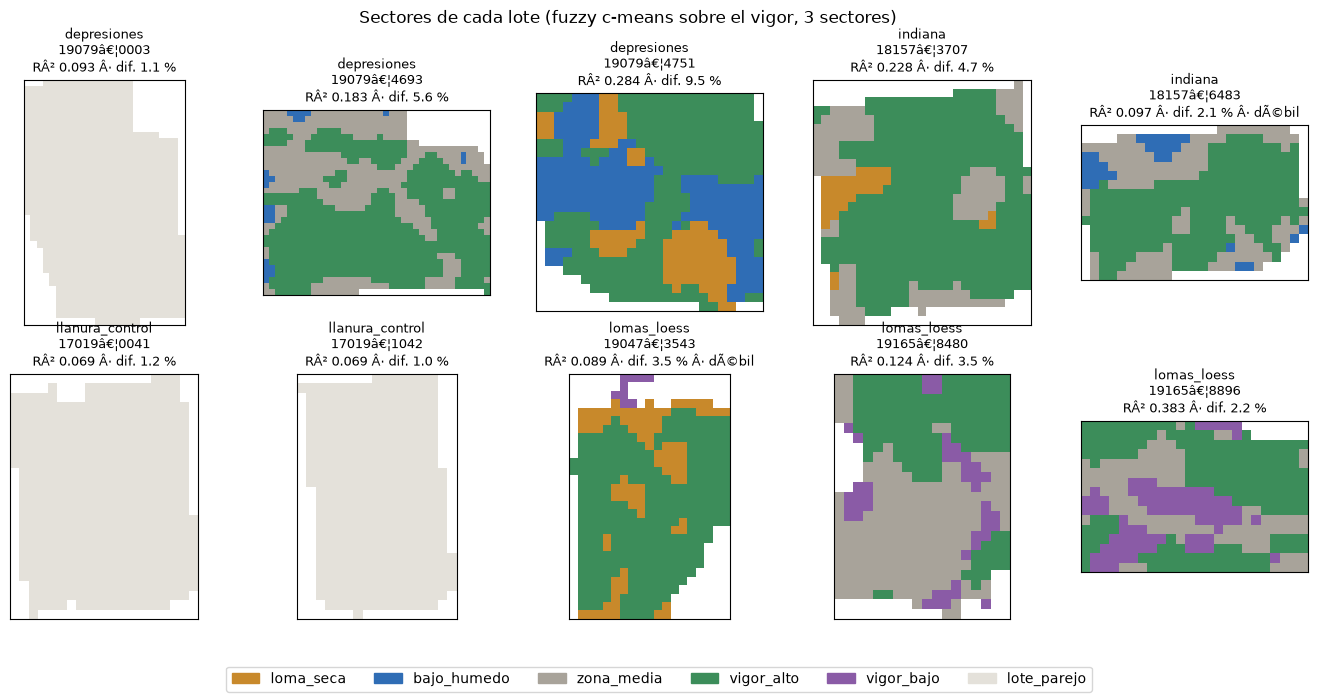

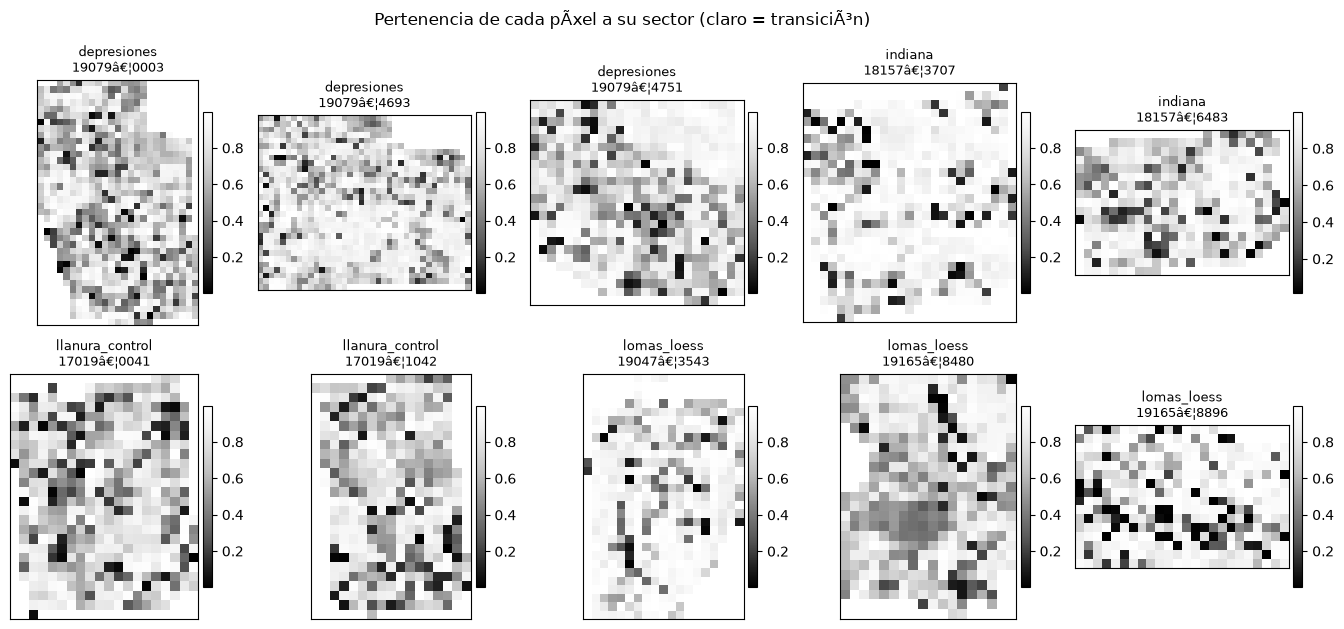

In [22]:
TIPOS_SECTOR = ["loma_seca", "bajo_humedo", "zona_media", "vigor_alto", "vigor_bajo", "lote_parejo"]
COLORES_SECTOR = ["#C8892B", "#2F6DB5", "#A8A39A", "#3C8D5A", "#8A5BA6", "#E4E1DA"]

if HAY_DATOS:
    mapa = sectores_px.merge(rasgos[["id_lote", "sector", "sector_id", "tipo", "estado_sectores"]],
                             on=["id_lote", "sector"])
    mapa.loc[mapa["estado_sectores"] == "lote_parejo", "tipo"] = "lote_parejo"
    sub = {i: f'RÂ² {r.r2_validacion:.3f} Â· dif. {r.dif_vigor_validacion_pct:.1f} %'
              + (" Â· dÃ©bil" if r.estado_sectores == "sectores_debiles" else "") for i, r in estado.iterrows()}
    dibujar_lotes(mapa, "tipo", "Sectores de cada lote (fuzzy c-means sobre el vigor, 3 sectores)",
                  categorias=TIPOS_SECTOR, colores=COLORES_SECTOR, subtitulos=sub)
    dibujar_lotes(mapa, "pertenencia", "Pertenencia de cada pÃ­xel a su sector (claro = transiciÃ³n)", cmap="Greys_r")
else:
    print("Faltan los datos de lotes: queda en espera.")

**Un lote de ejemplo, aÃ±o por aÃ±o.** Cada punto es un aÃ±o: cuÃ¡nto mÃ¡s o menos vigor tuvo cada sector que el promedio del lote, separado por tipo de aÃ±o. Es lo que muestra la ficha del sector en la app.

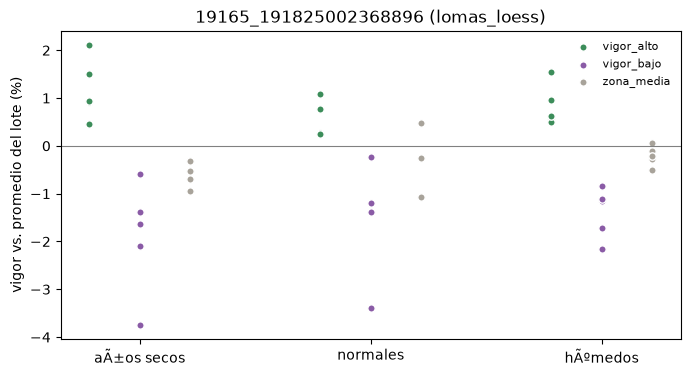

mediana                p10                p90             n_anios  \
clase_anio  humedo normal seco humedo normal seco humedo normal seco  humedo   
tipo                                                                           
vigor_alto     0.6    0.5  0.9    0.5    0.3  0.6    1.3    1.0  1.9     5.0   
vigor_bajo    -1.2   -1.3 -1.6   -2.0   -2.8 -3.1   -1.0   -0.5 -0.9     5.0   
zona_media    -0.2   -0.3 -0.5   -0.4   -0.8 -0.8   -0.0    0.3 -0.3     5.0   

                        
clase_anio normal seco  
tipo                    
vigor_alto    4.0  5.0  
vigor_bajo    4.0  5.0  
zona_media    4.0  5.0

In [23]:
if HAY_DATOS:
    con = estado[estado["estado_sectores"] == "con_sectores"]
    ejemplo = con["r2_validacion"].idxmax() if len(con) else lotes["id_lote"].iloc[0]
    s = serie[serie["id_lote"] == ejemplo].merge(rasgos[["id_lote", "sector", "tipo"]], on=["id_lote", "sector"])
    fig, eje = plt.subplots(figsize=(8, 4))
    pos = {"seco": 0, "normal": 1, "humedo": 2}
    colores = dict(zip(TIPOS_SECTOR, COLORES_SECTOR))
    for j, (tipo, t) in enumerate(s.groupby("tipo")):
        x = t["clase_anio"].map(pos) + (j - 1) * 0.22
        eje.scatter(x, t["vigor_rel_pct"], color=colores[tipo], label=tipo, s=28, edgecolor="white")
    eje.axhline(0, color="gray", lw=0.8)
    eje.set_xticks(range(3)); eje.set_xticklabels(["aÃ±os secos", "normales", "hÃºmedos"])
    eje.set_ylabel("vigor vs. promedio del lote (%)")
    eje.set_title(f"{ejemplo} ({lotes.set_index('id_lote').loc[ejemplo, 'paisaje']})")
    eje.legend(frameon=False, fontsize=8)
    plt.show()
    display(por_clase[por_clase["id_lote"] == ejemplo]
            .merge(rasgos[["id_lote", "sector", "tipo"]], on=["id_lote", "sector"])
            .pivot(index="tipo", columns="clase_anio", values=["mediana", "p10", "p90", "n_anios"]).round(1))
else:
    print("Faltan los datos de lotes: queda en espera.")

## 15. Guardar las tablas

Tres tablas en `backend/Datos/` (CSV, claves primero, faltante = celda vacÃ­a):

- `punto1_sectores.csv`: un pÃ­xel por fila: `fips, id_lote, px_id, estado_sectores, sector_id, tipo, pertenencia`. En los lotes parejos, `sector_id`, `tipo` y `pertenencia` quedan vacÃ­os.
- `punto1_sectores_resumen.csv`: un sector por fila: superficie, rasgos (terreno 3DEP, suelo, drenaje con caÃ±os, % de otro cultivo), confianza y el resultado de la validaciÃ³n del lote. Los lotes parejos van en una sola fila, sin sector.
- `punto1_sectores_anual.csv`: un sector por aÃ±o: `vigor_rel_pct`, tipo de aÃ±o, cultivo y cantidad de imÃ¡genes.

De acÃ¡ sale despuÃ©s lo que lee el front (`sectores/<id_lote>.geojson` y `.json`): eso todavÃ­a no estÃ¡.

In [24]:
CARPETA_SALIDA = RAIZ / "backend" / "Datos"

if HAY_DATOS:
    CARPETA_SALIDA.mkdir(parents=True, exist_ok=True)
    m = mapa.copy()
    parejo = m["estado_sectores"] == "lote_parejo"
    m["sector_id"] = m["sector_id"].astype("Int64").mask(parejo)
    m["tipo"] = m["tipo"].mask(parejo)
    m["pertenencia"] = m["pertenencia"].mask(parejo)
    m[["fips", "id_lote", "px_id", "estado_sectores", "sector_id", "tipo", "pertenencia"]] \
        .sort_values(["id_lote", "px_id"]).round(3) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores.csv", index=False)

    # Lotes con sectores: una fila por sector. Lotes parejos: una sola fila, sin sector.
    cols = ["fips", "id_lote", "estado_sectores", "sector_id", "tipo", "n_px", "area_ha", "pct_lote",
            "confianza", "pct_anios_consistente", "pertenencia_media", "elev_rel_m", "pendiente_3dep_pct",
            "twi_3dep", "aws0_150_mm", "clase_drenaje", "pct_drenaje_canos", "pct_otro_cultivo",
            "vigor_medio_z", "vigor_seco_z", "vigor_humedo_z",
            "r2_validacion", "dif_vigor_validacion_pct", "anios_validacion"]
    con_sectores = rasgos[rasgos["estado_sectores"] != "lote_parejo"]
    parejos = (rasgos[rasgos["estado_sectores"] == "lote_parejo"]
               .groupby(["fips", "id_lote"], as_index=False)
               .agg(estado_sectores=("estado_sectores", "first"), n_px=("n_px", "sum"),
                    r2_validacion=("r2_validacion", "first"),
                    dif_vigor_validacion_pct=("dif_vigor_validacion_pct", "first"),
                    anios_validacion=("anios_validacion", "first")))
    parejos["area_ha"] = parejos["n_px"] * 0.09
    salida = pd.concat([con_sectores, parejos], ignore_index=True).reindex(columns=cols)
    salida["sector_id"] = salida["sector_id"].astype("Int64")
    salida.sort_values(["id_lote", "sector_id"]).round(3) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores_resumen.csv", index=False)

    a = serie.merge(rasgos[["id_lote", "sector", "sector_id", "estado_sectores"]], on=["id_lote", "sector"])
    a = a[a["estado_sectores"] != "lote_parejo"]
    a[["fips", "id_lote", "sector_id", "anio", "cultivo", "clase_anio", "vigor_rel_pct", "n_px_con_dato",
       "n_obs_jul_ago"]].sort_values(["id_lote", "sector_id", "anio"]).round(2) \
        .to_csv(CARPETA_SALIDA / "punto1_sectores_anual.csv", index=False)

    for f in ["punto1_sectores.csv", "punto1_sectores_resumen.csv", "punto1_sectores_anual.csv"]:
        print(f, len(pd.read_csv(CARPETA_SALIDA / f)), "filas")
else:
    print("Faltan los datos de lotes: queda en espera.")

punto1_sectores.csv 5334 filas
punto1_sectores_resumen.csv 24 filas
punto1_sectores_anual.csv 315 filas


## PrÃ³ximos pasos

- [ ] Revisar los sectores con alguien que conozca la zona, mirando los mapas junto con una imagen satelital: los sectores chicos (1â€“4 % del lote) pueden ser vÃ­as de agua o bajos que se anegan.
- [ ] Acordar con el front cÃ³mo se muestra `sectores_debiles`: `estado_sectores` es un campo firme del contrato (`INFO.md`), asÃ­ que sumarlo sube la versiÃ³n a 1.0. Sumar tambiÃ©n los tipos nuevos (`vigor_alto`, `vigor_bajo`) y `textos.json`.
- [ ] Generar lo que lee el front: `sectores/<id_lote>.geojson` (polÃ­gonos a partir de la grilla) y `sectores/<id_lote>.json` (ficha), con `version_contrato`.
- [ ] Repetir cuando lleguen mÃ¡s pasadas de Landsat: hoy 26 de los 260 lote-aÃ±os no tienen ninguna de julioâ€“agosto (7 en 2009, 6 en 2024). Sentinel-2 no sirve para llenarlos por ahora: su vigor relativo coincide poco con el de Landsat (correlaciÃ³n mediana 0,53).
- [ ] Probar el lidar de 1 m de 3DEP si llega (hoy se usa el DEM de 10 m).
- [ ] Revisar los umbrales (RÂ², diferencia de vigor, consistencia, otro cultivo, nombres) con mÃ¡s lotes.
- [ ] Revisar si conviene pasar a 4 sectores: con la v1.3, de 3 a 4 el RÂ² sube 0,04.
- [ ] Mirar la estabilidad de los sectores ante cambios chicos en los datos: en un lote (19165_â€¦368896), sacar unos 8 pÃ­xel-aÃ±os con otro cultivo cambiÃ³ bastante la particiÃ³n (ARI 0,60 contra la anterior) y su "loma seca" pasÃ³ a "zona media". Con otras semillas, en cambio, los sectores no cambian (ARI de 0,98 o mÃ¡s).
- [ ] Prender `MIRAR_TEST` una sola vez, al final.
- [ ] Escribir `docs/ml/model_card_punto1.md`.
- [ ] Definir con el punto 2 cÃ³mo se pasa de sus puntos (`point_id`, en Story, McLean y Sumner) a estos lotes (`id_lote`, en otros condados).